<a href="https://colab.research.google.com/github/HiOkatani/dio-lab-HiOkatani/blob/main/SEDs_Dados_Microrrede.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pacotes


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import matplotlib.dates as mdates
import networkx as nx

# Pacotes para clusterização
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Teste inicial: Arquivos de  2025-09-01 a 2025-09-30

## 1. Leitura dos arquivos brutos

* Os arquivos retirados do InfluxDB são exportados pela plataforma priorizando o timestanp para cada uma das variáveis em _field. Torna-se necessário então a transformação das linhas em colunas utilizando a função "pivot_table".

* A coluna _time também é renomeada para timestamp, o usual para tratamento de dados
********
**DEVE SER TRANSFORMADA EM UMA FUNÇÃO **

In [ ]:
try:
  df = pd.read_csv('dados_20250711a20250731.csv', comment='#')
  print("Arquivo com dados brutos carregado com sucesso")
except FileNotFoundError:
  print("Arquivo com dados brutos não encontrado. Verifique o nome do arquivo")

columns = [
    "GridVoltageL1",
    "GridVoltageL2",
    "GridVoltageL3",
    "Inverter_Battery_current",
    "Inverter_Battery_power",
    "Inverter_Battery_voltage",
    "Inverter_Battery_SoC",
    "Inverter_Temperature",
    "pv1Power",
    "pv2Power",
    "Potencia_total_rede",
    "Total_load_power",
    ]

df_filtrado = df[df['_field'].isin(columns)][['_time','_field','_value']].copy()

# Convert the _value column to numeric, coercing errors to NaN
df_filtrado['_value'] = pd.to_numeric(df_filtrado['_value'], errors='coerce')

# Drop rows where _value is NaN after coercion
#df_filtrado.dropna(subset=['_value'], inplace=True)

# Construção do dataset com as colunas de field e seus valores
df_pivotado = df_filtrado.pivot_table(index='_time', columns='_field', values='_value')

# Adiciona Index para os dados de acordo com a timestamp
df_final = df_pivotado.reset_index()

# Renomear a coluna de tempo
df_final = df_final.rename(columns={'_time': 'timestamp'})

# Adicionar o sufixo '_value' às colunas de medição
colunas_para_renomear = {col: f"{col}_value" for col in df_final.columns if col != 'timestamp'}
df_final = df_final.rename(columns=colunas_para_renomear)

# Opcional: remover o nome do índice das colunas para um visual mais limpo
#df_final.columns.name = None


print("\nDataFrame Final Transformado:")
print(df_final.describe())

df1 = pd.read_csv('dados_formatados_250714_0816.csv')
print(df1.describe())

Arquivo com dados brutos carregado com sucesso

DataFrame Final Transformado:
_field  GridVoltageL1_value  GridVoltageL2_value  GridVoltageL3_value  \
count            358.000000           358.000000           358.000000   
mean             211.952757           209.284365           211.950880   
std               60.303675            59.544518            60.305806   
min                0.000000             0.000000             0.000000   
25%              228.282582           225.382398           228.225143   
50%              229.319306           226.311797           229.204974   
75%              230.220210           227.316040           230.212583   
max              232.345354           229.671082           232.722517   

_field  Inverter_Battery_current_value  Inverter_Battery_power_value  \
count                       358.000000                    358.000000   
mean                          0.498009                     20.758656   
std                           9.304643          

## 2. Análise de outliers do sistema de armazenamento

Realiza-se a análise de outliers para as variáveis referentes à bateria do sistema da microrrede, sendo as variáveis disponíveis:
* Corrente (A)
* Tensão (V)
* Potência (W)
* Porcentagem de carga (%)

A análise por quartis exclui valores NaN do estudo, apenas classificando a frequência com que aparecem no dataset, por isso sendo importante para a análise de outliers.

O mesmo procedimento pode ser adotado para outros equipamentos da microrrede.

In [ ]:
colunas_para_verificar = ['Inverter_Battery_voltage',
            'Inverter_Battery_current',
            'Inverter_Battery_power',
            'Inverter_SoC']

def verificar_outliers(df, colunas):
    print("--- Análise de Outliers usando o método IQR ---\n")

    # Dicionário para armazenar os DataFrames de outliers de cada coluna
    outliers_encontrados = {}

    # 2. Itere sobre cada coluna para fazer a análise
    for coluna in colunas: # Use the 'colunas' parameter here
        print(f"Analisando a coluna: '{coluna}'")

      # Calcula Q1, Q3 e IQR
        Q1 = df[coluna].quantile(0.25) # Use the passed df
        Q3 = df[coluna].quantile(0.75) # Use the passed df
        IQR = Q3 - Q1

      # Calcula os limites para detecção de outliers
        limite_inferior = Q1 - 1.5 * IQR
        limite_superior = Q3 + 1.5 * IQR

        print(f"  Q1: {Q1:.2f}, Q3: {Q3:.2f}, IQR: {IQR:.2f}")
        print(f"  Limites aceitáveis: [{limite_inferior:.2f}, {limite_superior:.2f}]")

      # 3. Identifica os outliers
        outliers = df[ # Use the passed df to create the boolean indexer
            (df[coluna] < limite_inferior) |
            (df[coluna] > limite_superior)
        ]

      # Guarda os outliers encontrados
        outliers_encontrados[coluna] = outliers

        print(f"  -> {len(outliers)} outliers encontrados.\n")


    # 4. Opcional: Visualizar alguns dos outliers encontrados
    # Por exemplo, para ver os outliers de 'Inverter_Battery_current'
    print("\n--- Exemplo: Visualizando outliers de 'Inverter_Battery_current' ---")
    if 'Inverter_Battery_current' in outliers_encontrados and not outliers_encontrados['Inverter_Battery_current'].empty:
        display(outliers_encontrados['Inverter_Battery_current'].head())
    else:
        print("Nenhum outlier encontrado para esta coluna.")
    return outliers_encontrados # Return the dictionary

## 3. Manipulação de dataframe para análise gráfica



1.   Configura-se a coluna timestamp para ser o index dos gráficos
2.   A coluna timestamp é convertida para o formato datetime do pandas



In [ ]:
# --- PREPARAÇÃO (execute apenas uma vez) ---
# Verifica se a coluna 'time' existe no DataFrame
if 'time' in df1.columns:
    print("Coluna 'time' encontrada. Configurando o índice...")

    # 1. Converte a coluna 'time' para o formato datetime
    df1['time'] = pd.to_datetime(df1['time'])

    # 2. Define a coluna 'time' como o novo índice do DataFrame
    df1 = df1.set_index('time')

    print("Índice de tempo configurado com sucesso.")

else:
    print("ERRO: Coluna 'time' não encontrada no DataFrame.")
# ----------------------------------------------


Dado que em testes anteriores observou-se um valor negativo de tensão nas bateias, realiza-se o plot das variáveis para verificar quando o fenômeno ocorre:

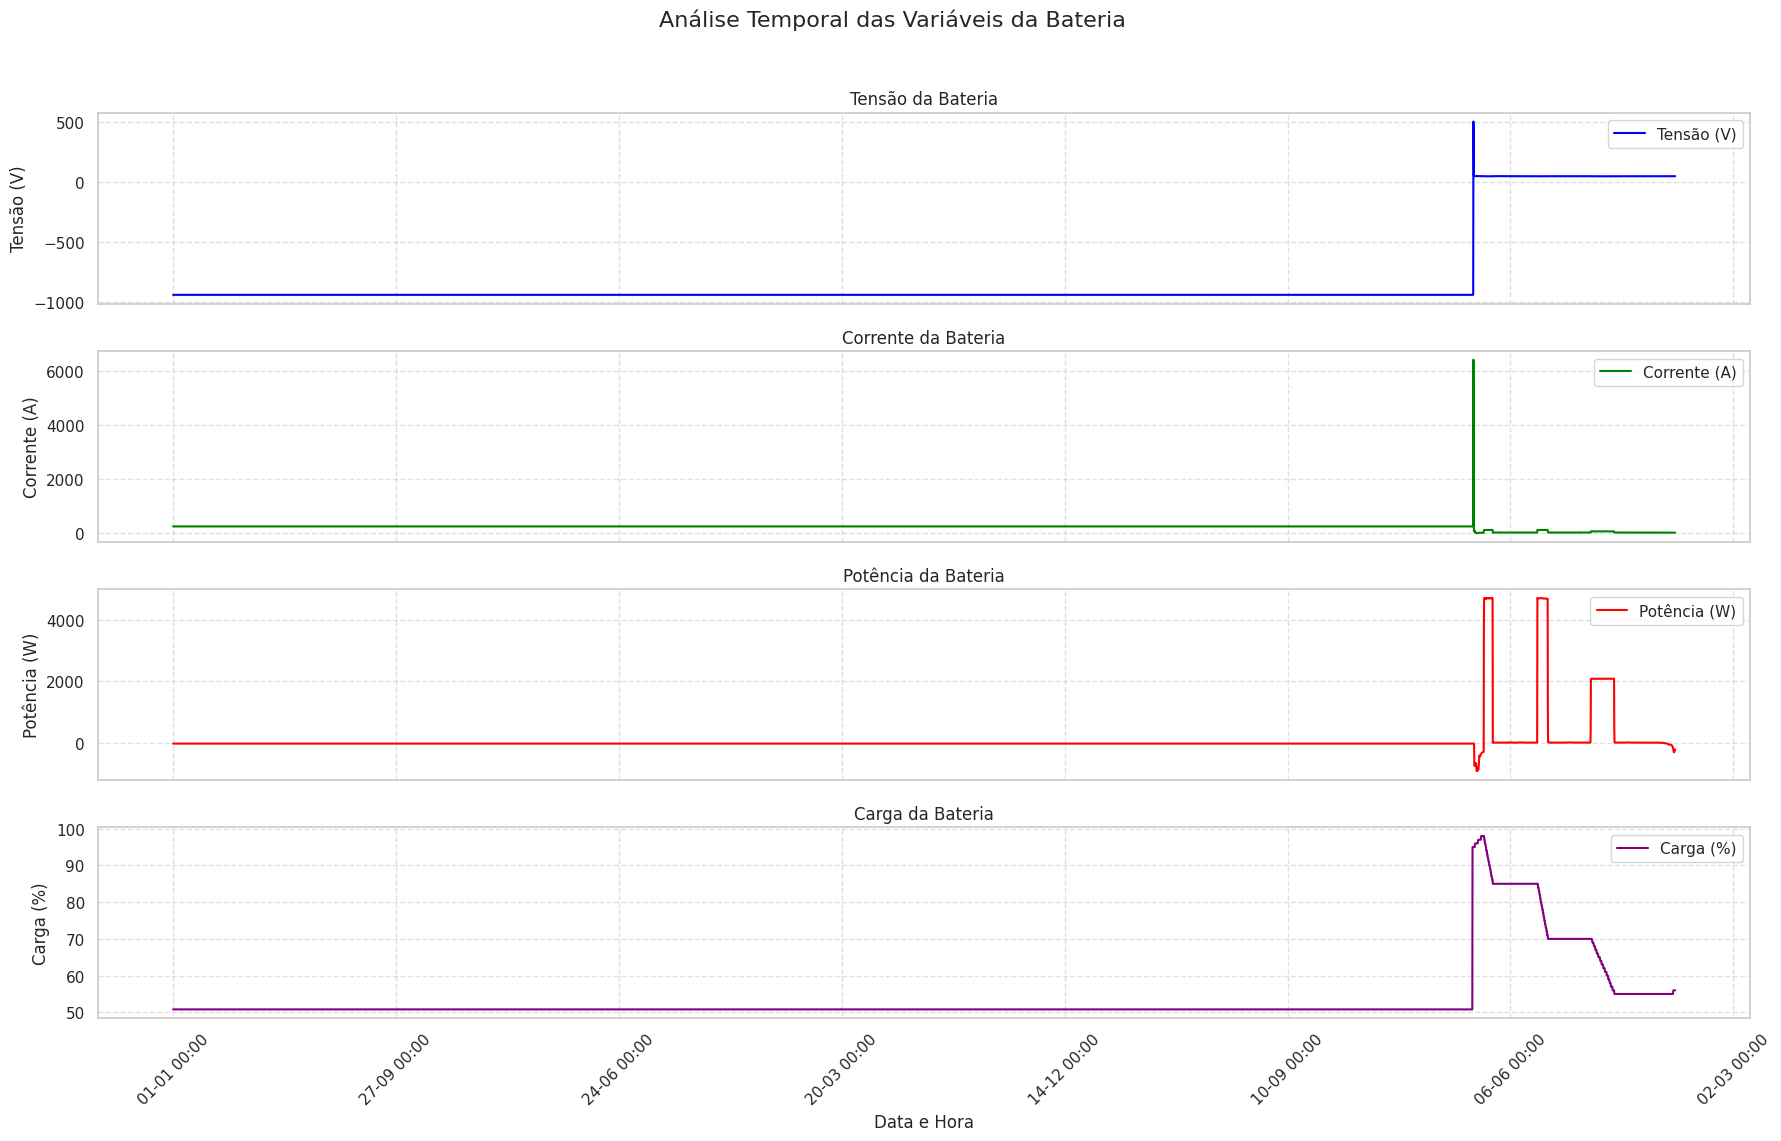

In [ ]:
# --- PLOTAGEM GERAL ---

# Cria a figura e os 8 subplots (4 linhas, 2 colunas)
# sharex=True faz com que o zoom em um gráfico se aplique a todos
fig, ax = plt.subplots(4, 1, figsize=(18, 12), sharex=True)
fig.suptitle('Análise Temporal das Variáveis da Bateria', fontsize=16)

# 1. Plot da Tensão da Bateria (no primeiro subplot da primeira linha)
ax[0].plot(df1.index, df1['Inverter_Battery_voltage'], label='Tensão (V)', color='blue')
ax[0].set_ylabel('Tensão (V)')
ax[0].set_title('Tensão da Bateria')
ax[0].grid(True, linestyle='--', alpha=0.6)
ax[0].legend()

# 2. Plot da Corrente da Bateria (no primeiro subplot da segunda linha)
ax[1].plot(df1.index, df1['Inverter_Battery_current'], label='Corrente (A)', color='green')
ax[1].set_ylabel('Corrente (A)')
ax[1].set_title('Corrente da Bateria')
ax[1].grid(True, linestyle='--', alpha=0.6)
ax[1].legend()

# 3. Plot da Potência da Bateria (no primeiro subplot da terceira linha)
ax[2].plot(df1.index, df1['Inverter_Battery_power'], label='Potência (W)', color='red')
ax[2].set_ylabel('Potência (W)')
ax[2].set_title('Potência da Bateria')
ax[2].grid(True, linestyle='--', alpha=0.6)
ax[2].legend()

# 4. Plot da Carga da Bateria (no primeiro subplot da quarta linha)
ax[3].plot(df1.index, df1['Inverter_SoC'], label='Carga (%)', color='purple')
ax[3].set_ylabel('Carga (%)')
ax[3].set_title('Carga da Bateria')
ax[3].grid(True, linestyle='--', alpha=0.6)
ax[3].legend()


# Formatando o eixo X para mostrar as datas de forma legível (aplicado ao último subplot com sharex=True)
ax[3].xaxis.set_major_formatter(mdates.DateFormatter('%d-%m %H:%M'))
plt.xticks(rotation=45)
plt.xlabel('Data e Hora')


# Melhora o espaçamento entre os plots
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

Para o caso apresentado em 07/2025, observa-se que a tensão negative tem grandes chances de ser uma representação de quando o sistema encontra-se em repouso ou bypass pelo inversor.

## 4. Teste de clustering por K-Means
Realizado somente para o SoC


In [ ]:
# Utilizaremos o df1 - dados_formatados_250714_0816.csv por ter mais pontos
print(df1.head())
# 1. Features da bateria
features = ['Inverter_Battery_voltage',
            'Inverter_Battery_current',
            'Inverter_Battery_power',
            'Inverter_SoC']

#Criação de um novo df apenas com as colunas de features
df_cluster = df1[features].dropna()

#2. Escalonamento
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_cluster)

# 3. Treinar o modelo K-Means
kmeans = KMeans(n_clusters=6, random_state=42, n_init='auto')
kmeans.fit(df_scaled)

# 4. Adicionar os resultados (os clusters) de volta ao DataFrame
df_cluster['cluster'] = kmeans.labels_

# 5. Analisar os clusters para entender o que cada um representa
cluster_analysis = df_cluster.groupby('cluster')[features].mean()

print("Análise dos Clusters (valores médios por cluster):")
display(cluster_analysis)




                        time  GridVoltageL1  GridVoltageL2  GridVoltageL3  \
0  2025-04-07 15:06:00-03:00     226.260000     222.320000     226.180000   
1  2025-04-07 15:07:00-03:00     226.466667     222.316667     226.300000   
2  2025-04-07 15:08:00-03:00     226.566667     222.400000     226.350000   
3  2025-04-07 15:09:00-03:00     226.860000     222.580000     226.460000   
4  2025-04-07 15:10:00-03:00     226.933333     222.716667     226.566667   

   Inverter_Battery_current  Inverter_Battery_power  Inverter_Battery_voltage  \
0                227.133333              -18.548333                    -942.0   
1                227.133333              -18.548333                    -942.0   
2                227.133333              -18.548333                    -942.0   
3                227.133333              -18.548333                    -942.0   
4                227.133333              -18.548333                    -942.0   

   Inverter_SoC  Inverter_Temperature  Potencia_to

,Inverter_Battery_voltage,Inverter_Battery_current,Inverter_Battery_power,Inverter_SoC
cluster,,,,
0,-942.000000,227.133333,-18.548333,50.806667
1,49.918150,0.308663,14.936139,77.653061
2,430.950000,5355.475917,-18.548333,95.000000
3,49.078142,95.466341,4684.607280,84.270881
4,49.387433,11.771585,576.094474,57.250702
5,-30.365946,17.409617,-499.692993,96.608844


## 5. Método do cotovelo

In [ ]:
# Supondo que 'X_scaled' são seus dados já escalonados e prontos para a clusterização
# X_scaled = scaler.fit_transform(df_features)

def cluster_elbow_analysis(df,features, k_range):
    #Criação de um novo df apenas com as colunas de features
    df_cluster = df[features].dropna()
    #2. Escalonamento
    scaler = StandardScaler()
    df_scaled = scaler.fit_transform(df_cluster)
    # Lista para armazenar os valores de inercia (WCSS
    inertia = []
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
        kmeans.fit(df_scaled)
        inertia.append(kmeans.inertia_)

    # Plotando o gráfico do cotovelo
    plt.figure(figsize=(10, 6))
    plt.plot(k_range, inertia, marker='o', linestyle='--')
    plt.xlabel('Número de Clusters (k)')
    plt.ylabel('Inércia (WCSS)')
    plt.title('Método do Cotovelo para Encontrar o k Ideal')
    plt.xticks(k_range)
    plt.grid(True)
    plt.show()
    return None

## 6. Método silhueta

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

def cluster_silhouette_analysis(df, features, k_range):
  #Criação de um novo df apenas com as colunas de features
    df_cluster = df[features].dropna()
    #2. Escalonamento
    scaler = StandardScaler()
    df_scaled = scaler.fit_transform(df_cluster)

# Supondo que 'X_scaled' são seus dados já escalonados
    silhouette_scores = []
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
        kmeans.fit(df_scaled)
        labels = kmeans.labels_
        score = silhouette_score(df_scaled, labels)
        silhouette_scores.append(score)

    # Plotando o gráfico
    plt.figure(figsize=(10, 6))
    plt.plot(k_range, silhouette_scores, marker='o', linestyle='--')
    plt.xlabel('Número de Clusters (k)')
    plt.ylabel('Coeficiente de Silhueta Médio')
    plt.title('Análise de Silhueta para Encontrar o k Ideal')
    plt.xticks(k_range)
    plt.grid(True)
    plt.show()

## 7. **Clusterização** final

Para os dados entrados pelo método do cotovelo e da silhueta, observa-se que a redução eo pico, respectivamente, ocorrem entre 4 e 7 clusters. Que foram adotados para a análise final de clusters da bateria.

In [ ]:
# --- PASSO 1: Treinar o Modelo Final com k=7 ---
k_otimo = 7
kmeans_final = KMeans(n_clusters=k_otimo, random_state=42, n_init='auto')
kmeans_final.fit(df_scaled)

# Adicionar os labels do novo modelo ao nosso DataFrame de trabalho
# (df_cluster foi o DataFrame que usamos para criar as features para o cluster)
df_cluster['cluster'] = kmeans_final.labels_


# --- PASSO 2: Analisar os Centros dos Clusters ---
# Esta tabela é a nossa "legenda". Usaremos ela para nomear cada cluster.
# Agrupamos pelo novo 'cluster' e olhamos a média das colunas ORIGINAIS.
cluster_analysis_final = df_cluster.groupby('cluster')[[
    'Inverter_Battery_voltage', 'Inverter_Battery_current',
    'Inverter_Battery_power', 'Inverter_SoC'
]].mean()

print("--- Análise dos 7 Clusters Encontrados ---")
display(cluster_analysis_final)

--- Análise dos 7 Clusters Encontrados ---


,Inverter_Battery_voltage,Inverter_Battery_current,Inverter_Battery_power,Inverter_SoC
cluster,,,,
0,-942.000000,227.133333,-18.548333,50.806667
1,49.916383,0.361064,17.490500,77.634097
2,430.950000,5355.475917,-18.548333,95.000000
3,49.078142,95.466341,4684.607280,84.270881
4,49.542717,-0.061268,-3.520560,55.036010
5,-30.365946,17.409617,-499.692993,96.608844
6,48.983775,42.562740,2084.397460,62.906667


## 8. Rotulando os resultados

In [ ]:
# --- PASSO 3: Mapear e Rotular os Clusters (Ação Manual) ---

mapa_de_estados = {
    0: 'Estado A (Parado)',
    1: 'Estado B (Flutuação)',
    2: 'Estado C (Anomalia)',
    3: 'Estado D (Descarga rápida)',
    4: 'Estado E (Carga Lenta)',
    5: 'Estado F (Carga rápida/ Média)',
    6: 'Estado G (Descarga Média)'
}

# Criar a coluna final com os nomes descritivos
df_cluster['estado_bateria'] = df_cluster['cluster'].map(mapa_de_estados)


# --- PASSO 4: Ver o Resultado Final ---
print("\n--- Distribuição Final dos Estados de Operação (k=7) ---")

# Contar quantas vezes cada estado ocorreu
print("\nContagem de ocorrências por estado:")
print(df_cluster['estado_bateria'].value_counts())

# Calcular a porcentagem de tempo em cada estado
print("\nPorcentagem de tempo em cada estado:")
print(df_cluster['estado_bateria'].value_counts(normalize=True) * 100)

#  Criar uma nova coluna 'estado_bateria' usando o mapa
# A função .map() substitui cada número de cluster pelo seu respectivo texto
#df_cluster['estado_bateria'] = df_cluster['cluster'].map(mapa_de_estados)

# Investigar as anomalias
# Filtrar e ver todos os momentos de anomalia
print("\nExemplos de momentos de anomalia:")
# Para visualizar, podemos juntar os resultados com o timestamp original
# Supondo que os índices de df_cluster e df_final correspondem
df_com_estados = df_final.join(df_cluster['estado_bateria'])

display(df_com_estados[df_com_estados['estado_bateria'].str.contains('Anomalia', na=False)].head())


--- Distribuição Final dos Estados de Operação (k=7) ---

Contagem de ocorrências por estado:
estado_bateria
Estado A (Parado)                 5830
Estado B (Flutuação)               393
Estado E (Carga Lenta)             274
Estado G (Descarga Média)          105
Estado D (Descarga rápida)          87
Estado F (Carga rápida/ Média)      49
Estado C (Anomalia)                  2
Name: count, dtype: int64

Porcentagem de tempo em cada estado:
estado_bateria
Estado A (Parado)                 86.498516
Estado B (Flutuação)               5.830861
Estado E (Carga Lenta)             4.065282
Estado G (Descarga Média)          1.557864
Estado D (Descarga rápida)         1.290801
Estado F (Carga rápida/ Média)     0.727003
Estado C (Anomalia)                0.029674
Name: proportion, dtype: float64

Exemplos de momentos de anomalia:


,timestamp,GridVoltageL1_value,GridVoltageL2_value,GridVoltageL3_value,Inverter_Battery_current_value,Inverter_Battery_power_value,Inverter_Battery_voltage_value,Inverter_Temperature_value,Potencia_total_rede_value,Total_load_power_value,pv1Power_value,pv2Power_value,estado_bateria


## 9. Teste EBAM

In [ ]:
import pandas as pd
import numpy as np

# Supondo que 'df_cluster_abs' é o seu DataFrame final,
# já com a coluna 'cluster' (com os números de 0 a 6) e
# a coluna 'estado_bateria' (com os nomes descritivos).

# --- PASSO 1: Isolar a Sequência de Estados ---

# O importante para a análise de eventos é a MUDANÇA de estado.
# Vamos criar uma série temporal que contém apenas o estado (cluster) em cada momento.
estados_temporais = df_cluster['cluster']

# Identifica apenas os momentos em que o estado mudou
mudancas_de_estado = estados_temporais[estados_temporais.shift() != estados_temporais]

print(f"Total de pontos de dados: {len(estados_temporais)}")
print(f"Total de mudanças de estado (eventos): {len(mudancas_de_estado)}")
print("\nSequência de mudanças de estado observada:")
display(mudancas_de_estado.head(10))


# --- PASSO 2: Criar os "I/O Vectors" (Vetores de Estado do Cluster) ---

# No artigo, o I/O Vector é um vetor binário. Para nós, será um vetor
# one-hot encoded que representa em qual cluster o sistema está.
# Usamos o pandas.get_dummies para criar isso facilmente.
vetores_de_estado = pd.get_dummies(mudancas_de_estado)

print("\n--- Vetores de Estado (equivalente aos I/O Vectors do artigo) ---")
print("Cada linha representa um estado, com '1' na coluna do cluster ativo.")
display(vetores_de_estado.head())


# --- PASSO 3: Calcular os "Event Vectors" ---

# O artigo define um evento como a diferença entre dois vetores de estado consecutivos: e = u(i+1) - u(i)
# O método .diff() do pandas faz exatamente isso.
vetores_de_evento = vetores_de_estado.diff()

# O primeiro evento é sempre NaN (pois não há estado anterior), então o removemos.
vetores_de_evento = vetores_de_evento.dropna()

# Convertendo para inteiros para ficar igual ao artigo {-1, 0, 1}
vetores_de_evento = vetores_de_evento.astype(int)

print("\n--- Vetores de Evento (calculados como no artigo) ---")
print("Cada linha é um evento: -1 no estado de origem, +1 no estado de destino.")
display(vetores_de_evento.head())

Total de pontos de dados: 6740
Total de mudanças de estado (eventos): 10

Sequência de mudanças de estado observada:


,cluster
0,0
5830,5
5834,2
5836,5
5881,3
5921,1
6121,3
6168,1
6361,6
6466,4



--- Vetores de Estado (equivalente aos I/O Vectors do artigo) ---
Cada linha representa um estado, com '1' na coluna do cluster ativo.


,0,1,2,3,4,5,6
0,True,False,False,False,False,False,False
5830,False,False,False,False,False,True,False
5834,False,False,True,False,False,False,False
5836,False,False,False,False,False,True,False
5881,False,False,False,True,False,False,False



--- Vetores de Evento (calculados como no artigo) ---
Cada linha é um evento: -1 no estado de origem, +1 no estado de destino.


,0,1,2,3,4,5,6
5830,1,0,0,0,0,1,0
5834,0,0,1,0,0,1,0
5836,0,0,1,0,0,1,0
5881,0,0,0,1,0,1,0
5921,0,1,0,1,0,0,0


## 10. Representação

--- Frequência das Transições Entre Clusters ---
(3, 1)    2
(0, 5)    1
(2, 5)    1
(5, 2)    1
(5, 3)    1
Name: count, dtype: int64


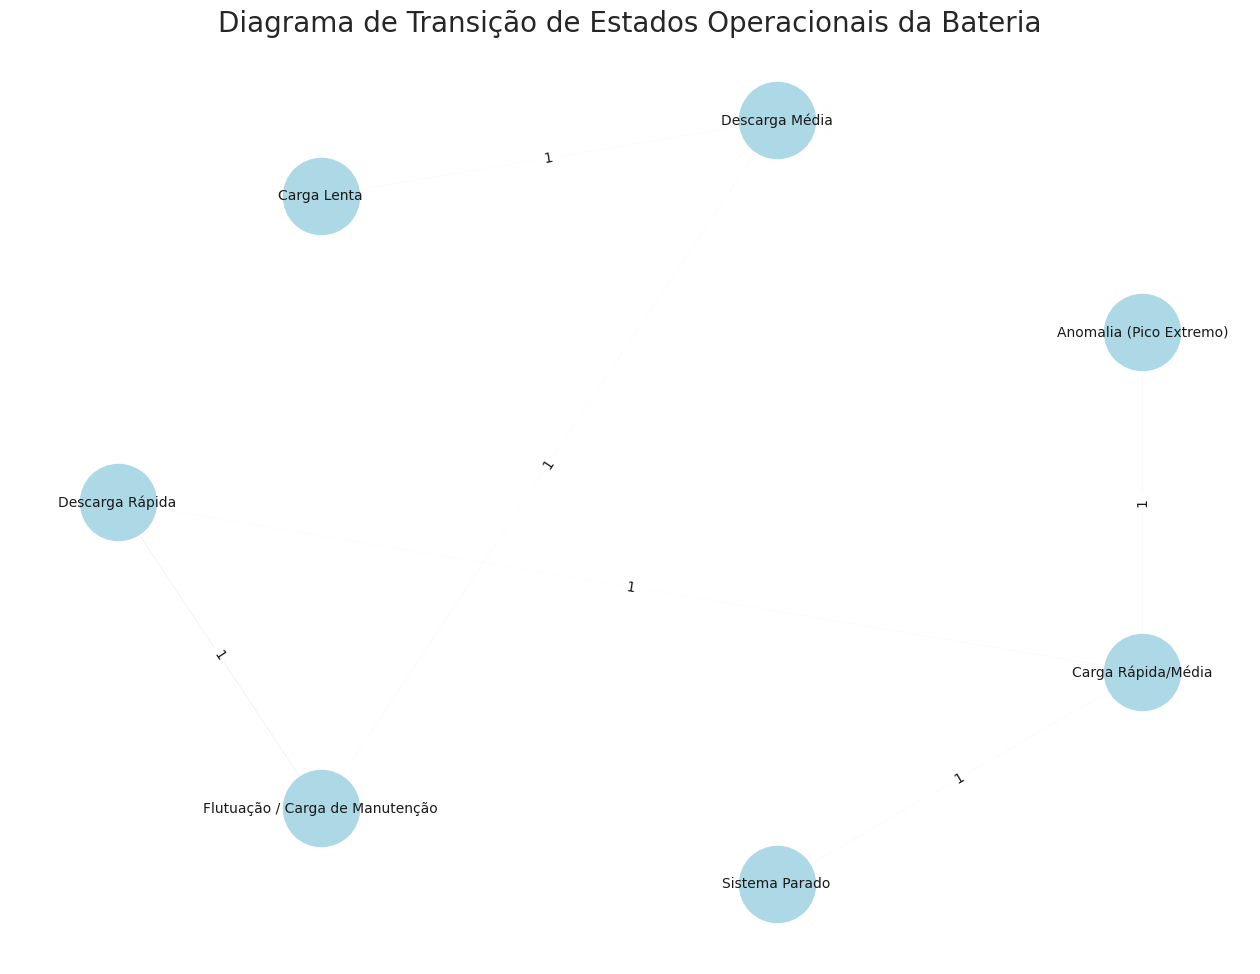

In [ ]:
# --- PRÉ-REQUISITOS (resultados do script anterior) ---

# Supondo que 'df_cluster_abs' e 'mudancas_de_estado' já existem.
# E o 'mapa_de_estados' que criamos na última etapa.
mapa_de_estados = {
    0: 'Sistema Parado',
    1: 'Flutuação / Carga de Manutenção',
    2: 'Anomalia (Pico Extremo)',
    3: 'Descarga Rápida',
    4: 'Carga Lenta',
    5: 'Carga Rápida/Média',
    6: 'Descarga Média'
}


# --- PASSO 1: Identificar e Contar as Transições ---

# Pega o estado de origem (todos exceto o último)
estados_origem = mudancas_de_estado.iloc[:-1].values
# Pega o estado de destino (todos exceto o primeiro)
estados_destino = mudancas_de_estado.iloc[1:].values

# Cria uma lista de tuplas, onde cada tupla é uma transição (origem, destino)
lista_de_transicoes = list(zip(estados_origem, estados_destino))

# Conta quantas vezes cada transição única ocorreu
contagem_transicoes = pd.Series(lista_de_transicoes).value_counts()

print("--- Frequência das Transições Entre Clusters ---")
print(contagem_transicoes.head())


# --- PASSO 2: Construir o Grafo com NetworkX ---

# Cria um grafo direcionado vazio
G = nx.DiGraph()

# Adiciona as arestas (transições) ao grafo
for (origem_id, destino_id), peso in contagem_transicoes.items():
    # Usa o mapa para obter os nomes legíveis dos estados
    nome_origem = mapa_de_estados.get(origem_id, f"Cluster {origem_id}")
    nome_destino = mapa_de_estados.get(destino_id, f"Cluster {destino_id}")

    G.add_edge(nome_origem, nome_destino, weight=peso)


# --- PASSO 3: Desenhar o Grafo ---

plt.figure(figsize=(16, 12))
# O layout 'shell' organiza os nós em um círculo, bom para diagramas de estado
pos = nx.shell_layout(G)

# Pega os pesos das arestas para desenhar setas mais grossas para transições frequentes
pesos = [G[u][v]['weight'] / 100 for u, v in G.edges()] # Escalonando para melhor visualização

# Desenha os nós
nx.draw_networkx_nodes(G, pos, node_size=3000, node_color='lightblue')

# Desenha as arestas
nx.draw_networkx_edges(G, pos, edgelist=G.edges(), width=pesos, arrows=True, arrowstyle='->', arrowsize=20)

# Desenha os rótulos dos nós
nx.draw_networkx_labels(G, pos, font_size=10, font_family='sans-serif')

# Desenha os rótulos das arestas (a contagem de transições)
edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

plt.title('Diagrama de Transição de Estados Operacionais da Bateria', size=20)
plt.axis('off') # Remove os eixos x e y
plt.show()

# Teste para dados de 05/25

Vamos verificar se os clusters encontrados para a bateria tem valores parecidos com os de julho, dado que o sistema apresentou, no período de maio uma operação sem falhas visíveis.



## 1. Análise inicial dos dados de 05/25

O timestamp encontra-se no formato: 2025-05-29 13:29:53.378019300-03:00. Esta precisão provoca erros de leitura pelo pandas para a produção de gráficos. É necessário colocá-lo m um timestamp que este possa ler.


In [ ]:
try:
    # Carregue o DataFrame, lendo a coluna 'time' como texto por segurança
    df_maio = pd.read_csv('dados_formatados.csv', low_memory=False, dtype={'time': str})

    # --- INÍCIO DA SOLUÇÃO MULTI-ETAPAS ---

    # 1. Crie uma série para guardar os resultados finais
    timestamps_finais = pd.Series(pd.NaT, index=df_maio.index)

    # 2. Defina uma lista de formatos para tentar, do mais específico para o mais geral
    formatos_para_tentar = [
        '%Y-%m-%d %H:%M:%S.%f%z',  # Formato com segundos fracionados
        '%Y-%m-%d %H:%M:%S%z'      # Formato sem segundos fracionados
    ]

    # Cópia da coluna original para irmos consumindo
    coluna_time_restante = df_maio['time'].copy()

    for fmt in formatos_para_tentar:
        # 3. Tenta converter o que ainda não foi convertido, usando o formato da vez
        conversao_parcial = pd.to_datetime(coluna_time_restante, format=fmt, errors='coerce')

        # 4. Atualiza nossa série final com os valores que foram convertidos com sucesso nesta etapa
        timestamps_finais = timestamps_finais.fillna(conversao_parcial)

        # 5. Atualiza a coluna restante, mantendo apenas o que AINDA não foi convertido
        coluna_time_restante = coluna_time_restante[conversao_parcial.isna()]

    # --- FIM DA SOLUÇÃO ---

    # Atribui a coluna totalmente convertida de volta ao DataFrame
    df_maio['time'] = timestamps_finais

    # --- Verificação Final ---
    erros_restantes = df_maio['time'].isna().sum()
    if erros_restantes > 0:
        print(f"\nAVISO FINAL: {erros_restantes} linhas AINDA não puderam ser convertidas.")
        print("Isso indica a existência de um terceiro formato ou de valores verdadeiramente nulos (nan).")
        # Mostra os valores que sobraram
        erros_df = df_maio[df_maio['time'].isna()]
        print("Exemplos de valores que sobraram sem conversão:")
        print(erros_df['time'].value_counts())
    else:
        print("\nSUCESSO TOTAL! Todas as linhas foram convertidas com sucesso.")

    print("\n--- Verificação da Coluna 'time' após conversão multi-etapas ---")
    print(df_maio['time'].dropna().head())
    print("\nTipo de dado da coluna 'time':", df_maio['time'].dtype)

    # Agora, finalmente, podemos definir como índice
    df_maio = df_maio.set_index('time')
    print("\nDataFrame com o novo índice de tempo:")
    print(df_maio.head())


except FileNotFoundError:
    print("Erro: O arquivo 'dados_formatados0905_2905Total.csv' não foi encontrado.")


SUCESSO TOTAL! Todas as linhas foram convertidas com sucesso.

--- Verificação da Coluna 'time' após conversão multi-etapas ---
0   2025-04-07 15:06:00-03:00
1   2025-04-07 15:07:00-03:00
2   2025-04-07 15:08:00-03:00
3   2025-04-07 15:09:00-03:00
4   2025-04-07 15:10:00-03:00
Name: time, dtype: datetime64[ns, UTC-03:00]

Tipo de dado da coluna 'time': datetime64[ns, UTC-03:00]

DataFrame com o novo índice de tempo:
                           GridVoltageL1  GridVoltageL2  GridVoltageL3  \
time                                                                     
2025-04-07 15:06:00-03:00     226.260000     222.320000     226.180000   
2025-04-07 15:07:00-03:00     226.466667     222.316667     226.300000   
2025-04-07 15:08:00-03:00     226.566667     222.400000     226.350000   
2025-04-07 15:09:00-03:00     226.860000     222.580000     226.460000   
2025-04-07 15:10:00-03:00     226.933333     222.716667     226.566667   

                           Inverter_Battery_current  Inverte

/tmp/ipython-input-2161044001.py:24: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  timestamps_finais = timestamps_finais.fillna(conversao_parcial)


Gerando Gráfico de Potência...


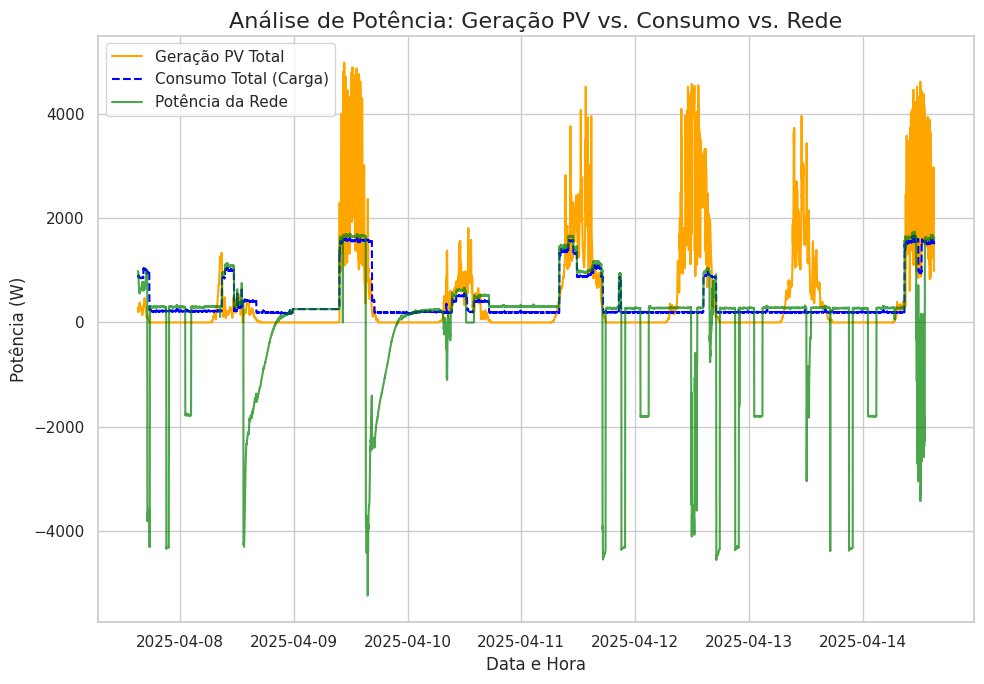


Gerando Gráfico de Tensão da Rede...


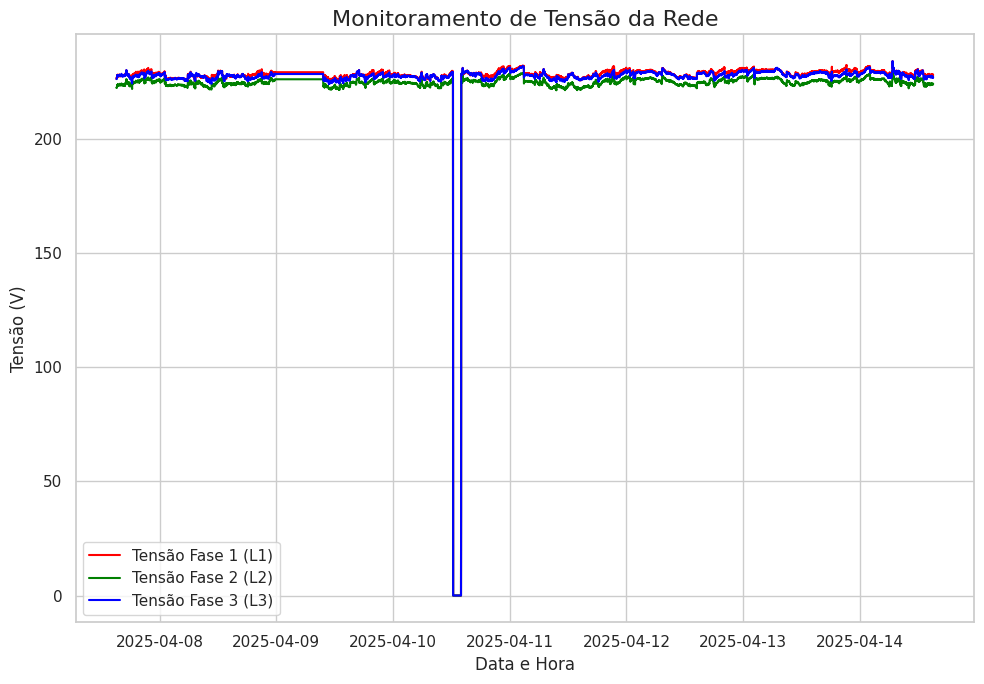


Gerando Gráfico da Bateria...


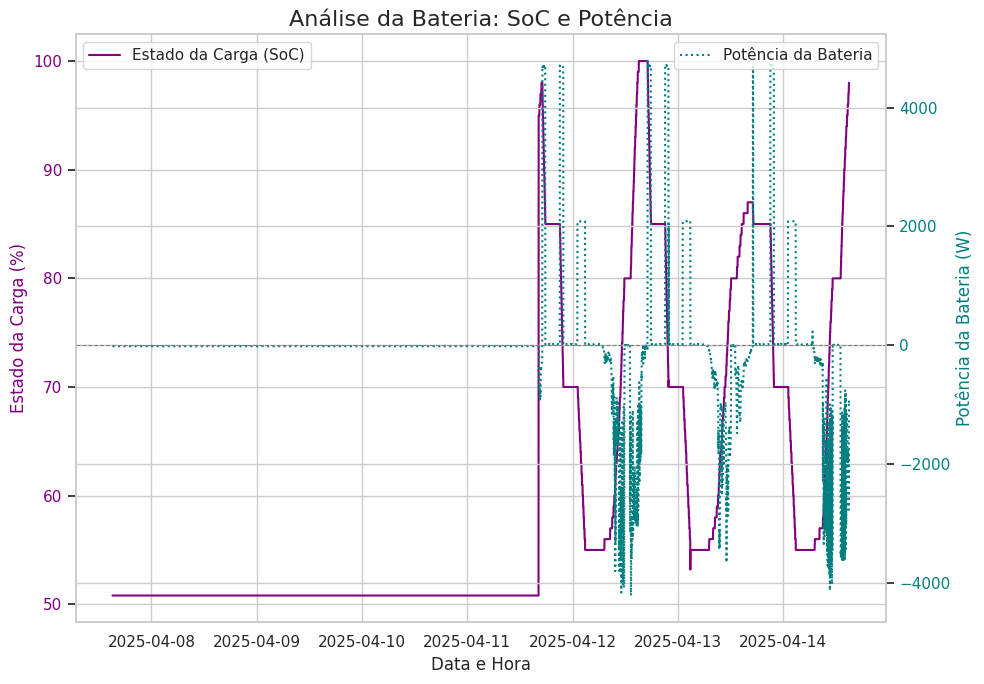

In [ ]:
# --- Parte 2: Geração dos Gráficos ---
# Configura o estilo dos gráficos
sns.set_theme(style="whitegrid")

# **Gráfico 1: Análise de Potência (Geração, Consumo e Rede)**
print("Gerando Gráfico de Potência...")
fig, ax1 = plt.subplots(figsize=(10, 7))

# Soma das potências dos painéis fotovoltaicos
df_maio['pv_total_power'] = df_maio['pv1Power'] + df_maio['pv2Power']

# Plotando as potências
ax1.plot(df_maio.index, df_maio['pv_total_power'], label='Geração PV Total', color='orange')
ax1.plot(df_maio.index, df_maio['Total_load_power'], label='Consumo Total (Carga)', color='blue', linestyle='--')
ax1.plot(df_maio.index, df_maio['Potencia_total_rede'], label='Potência da Rede', color='green', alpha=0.7)

ax1.set_title('Análise de Potência: Geração PV vs. Consumo vs. Rede', fontsize=16)
ax1.set_xlabel('Data e Hora', fontsize=12)
ax1.set_ylabel('Potência (W)', fontsize=12)
ax1.legend()
ax1.grid(True)
plt.tight_layout()
plt.show()


# **Gráfico 2: Tensão da Rede Elétrica**
print("\nGerando Gráfico de Tensão da Rede...")
fig, ax2 = plt.subplots(figsize=(10, 7))

ax2.plot(df_maio.index, df_maio['GridVoltageL1'], label='Tensão Fase 1 (L1)', color='red')
ax2.plot(df_maio.index, df_maio['GridVoltageL2'], label='Tensão Fase 2 (L2)', color='green')
ax2.plot(df_maio.index, df_maio['GridVoltageL3'], label='Tensão Fase 3 (L3)', color='blue')

ax2.set_title('Monitoramento de Tensão da Rede', fontsize=16)
ax2.set_xlabel('Data e Hora', fontsize=12)
ax2.set_ylabel('Tensão (V)', fontsize=12)
ax2.legend()
ax2.grid(True)
plt.tight_layout()
plt.show()


# **Gráfico 3: Análise da Bateria (Carga e Potência)**
print("\nGerando Gráfico da Bateria...")
fig, ax3 = plt.subplots(figsize=(10, 7))

# Eixo esquerdo para o Estado da Carga (SoC)
ax3.plot(df_maio.index, df_maio['Inverter_SoC'], label='Estado da Carga (SoC)', color='purple')
ax3.set_xlabel('Data e Hora', fontsize=12)
ax3.set_ylabel('Estado da Carga (%)', fontsize=12, color='purple')
ax3.tick_params(axis='y', labelcolor='purple')
ax3.legend(loc='upper left')

# Eixo direito para a Potência da Bateria
ax4 = ax3.twinx()
ax4.plot(df_maio.index, df_maio['Inverter_Battery_power'], label='Potência da Bateria', color='teal', linestyle=':')
ax4.set_ylabel('Potência da Bateria (W)', fontsize=12, color='teal')
ax4.tick_params(axis='y', labelcolor='teal')
ax4.legend(loc='upper right')
# Adiciona uma linha em 0 para ver carga/descarga
ax4.axhline(0, color='gray', linestyle='--', linewidth=0.8)


ax3.set_title('Análise da Bateria: SoC e Potência', fontsize=16)
fig.tight_layout()
plt.show()

In [ ]:
# # --- PASSO 1: SELECIONAR O DIA ---

# # Apenas mude a data dentro das aspas para o dia desejado ('ANO-MÊS-DIA')
# dia_especifico = df.loc['2025-05-15':'2025-05-23']
# df_dia = df.loc['2025-05-15':'2025-05-21']


# # --- PASSO 2: PLOTAR O GRÁFICO PARA ESSE DIA ---

# print(f"Gerando Gráfico de Potência para o dia {dia_especifico}...")

# # (Note que este código é idêntico ao anterior, apenas trocamos 'df' por 'df_dia')

# # Preenchemos os valores nulos com 0 para evitar erros na soma
# df_dia['pv1Power'] = df_dia['pv1Power'].fillna(0)
# df_dia['pv2Power'] = df_dia['pv2Power'].fillna(0)
# df_dia['Total_load_power'] = df_dia['Total_load_power'].fillna(0)
# df_dia['Potencia_total_rede'] = df_dia['Potencia_total_rede'].fillna(0)

# df_dia['pv_total_power'] = df_dia['pv1Power'] + df_dia['pv2Power']

# # Agora, plotamos usando o df_dia
# fig, ax1 = plt.subplots(figsize=(15, 7))
# ax1.plot(df_dia.index, df_dia['pv_total_power'], label='Geração PV Total', color='orange')
# ax1.plot(df_dia.index, df_dia['Total_load_power'], label='Consumo Total (Carga)', color='blue', linestyle='--')
# ax1.plot(df_dia.index, df_dia['Potencia_total_rede'], label='Potência da Rede', color='green', alpha=0.7)

# ax1.set_title(f'Análise de Potência - Dia {dia_especifico}', fontsize=16) # Título dinâmico
# ax1.set_xlabel('Hora do Dia', fontsize=12)
# ax1.set_ylabel('Potência (W)', fontsize=12)
# ax1.legend()
# ax1.grid(True)
# plt.tight_layout()
# plt.show()

# # **Gráfico 3: Análise da Bateria (Carga e Potência)**
# print("\nGerando Gráfico da Bateria...")
# fig, ax3 = plt.subplots(figsize=(10, 7))

# # Eixo esquerdo para o Estado da Carga (SoC)
# ax3.plot(df_dia.index, df_dia['Inverter_SoC'], label='Estado da Carga (SoC)', color='purple')
# ax3.set_xlabel('Data e Hora', fontsize=12)
# ax3.set_ylabel('Estado da Carga (%)', fontsize=12, color='purple')
# ax3.tick_params(axis='y', labelcolor='purple')
# ax3.legend(loc='upper left')

# # Eixo direito para a Potência da Bateria
# ax4 = ax3.twinx()
# ax4.plot(df_dia.index, df_dia['Inverter_Battery_power'], label='Potência da Bateria', color='teal', linestyle=':')
# ax4.set_ylabel('Potência da Bateria (W)', fontsize=12, color='teal')
# ax4.tick_params(axis='y', labelcolor='teal')
# ax4.legend(loc='upper right')
# # Adiciona uma linha em 0 para ver carga/descarga
# ax4.axhline(0, color='gray', linestyle='--', linewidth=0.8)


# ax3.set_title('Análise da Bateria: SoC e Potência', fontsize=16)
# fig.tight_layout()
# plt.show()


## 2. Análise de outlier da bateria

Com vase nos testes realizados para a leitura de setembro, realizam-se as mesmas análise de outlier para o mês de maio


In [ ]:
outliers_df_maio = verificar_outliers(df_maio, colunas_para_verificar) # Pass df_maio


--- Análise de Outliers usando o método IQR ---

Analisando a coluna: 'Inverter_Battery_voltage'
  Q1: -942.00, Q3: 49.73, IQR: 991.73
  Limites aceitáveis: [-2429.60, 1537.33]
  -> 0 outliers encontrados.

Analisando a coluna: 'Inverter_Battery_current'
  Q1: 0.26, Q3: 227.13, IQR: 226.87
  Limites aceitáveis: [-340.05, 567.44]
  -> 2 outliers encontrados.

Analisando a coluna: 'Inverter_Battery_power'
  Q1: -18.55, Q3: 3.40, IQR: 21.95
  Limites aceitáveis: [-51.47, 36.32]
  -> 2002 outliers encontrados.

Analisando a coluna: 'Inverter_SoC'
  Q1: 50.81, Q3: 70.00, IQR: 19.19
  Limites aceitáveis: [22.02, 98.79]
  -> 138 outliers encontrados.


--- Exemplo: Visualizando outliers de 'Inverter_Battery_current' ---


,GridVoltageL1,GridVoltageL2,GridVoltageL3,Inverter_Battery_current,Inverter_Battery_power,Inverter_Battery_voltage,Inverter_SoC,Inverter_Temperature,Potencia_total_rede,Total_load_power,pv1Power,pv2Power,pv_total_power
time,,,,,,,,,,,,,
2025-04-11 16:20:00-03:00,226.916667,222.533333,226.483333,6413.100000,-18.548333,507.0,95.0,98.0,1143.666667,1061.333333,755.333333,0.0,755.333333
2025-04-11 16:21:00-03:00,226.766667,222.366667,226.183333,4297.851833,-18.548333,354.9,95.0,98.0,1139.333333,1056.833333,742.166667,0.0,742.166667


## 3. Método do cotovelo

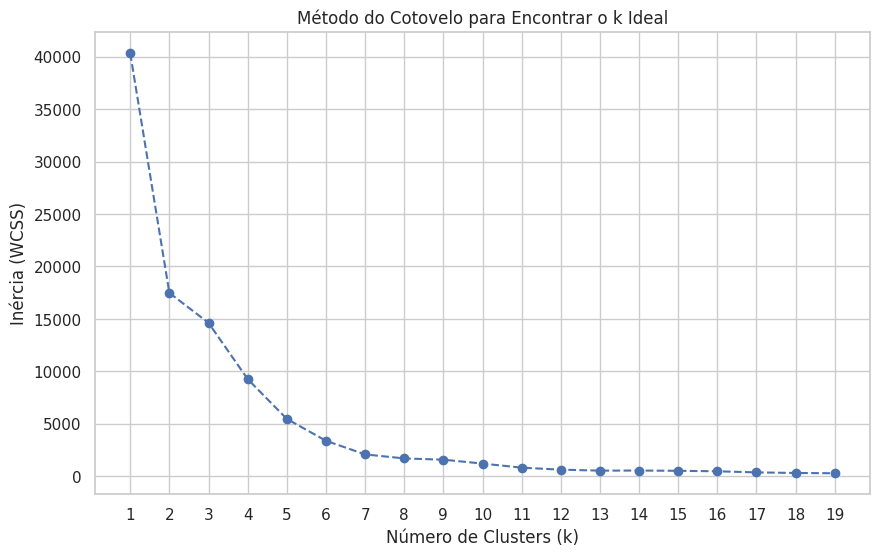

In [ ]:
cotovelo_df_maio = cluster_elbow_analysis(df_maio, features= features, k_range = range(1, 20))

## 4. Método silhueta

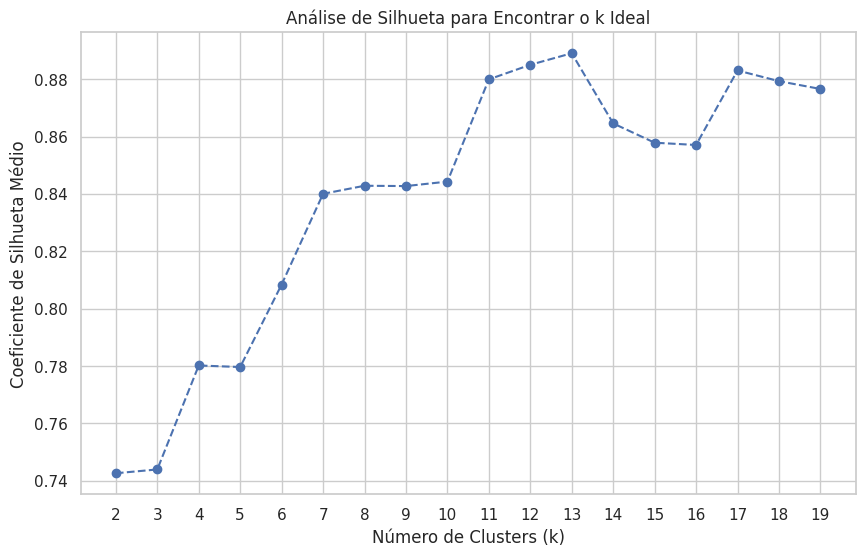

In [ ]:
silhueta_df_maio = cluster_silhouette_analysis(df_maio, features= features, k_range = range(2, 20))

## 5. Clusterização final
Pelo método da silhuta, escolhe-se utilizar 7 clusters, como a função anterior

In [ ]:
k_otimo_maio = 7
#Criação de um novo df apenas com as colunas de features
df_cluster_maio = df_maio[features].dropna()
#2. Escalonamento
scaler = StandardScaler()
df_scaled_maio = scaler.fit_transform(df_cluster_maio)

kmeans_final = KMeans(n_clusters=k_otimo_maio, random_state=42, n_init='auto')
kmeans_final.fit(df_scaled_maio)

# Adicionar os labels do novo modelo ao nosso DataFrame de trabalho
# (df_cluster foi o DataFrame que usamos para criar as features para o cluster)
df_cluster_maio['cluster'] = kmeans_final.labels_


# --- PASSO 2: Analisar os Centros dos Clusters ---
# Esta tabela é a nossa "legenda". Usaremos ela para nomear cada cluster.
# Agrupamos pelo novo 'cluster' e olhamos a média das colunas ORIGINAIS.
cluster_analysis_final_maio = df_cluster_maio.groupby('cluster')[[
    'Inverter_Battery_voltage', 'Inverter_Battery_current',
    'Inverter_Battery_power', 'Inverter_SoC'
]].mean()

print("--- Análise dos 7 Clusters Encontrados ---")
display(cluster_analysis_final_maio)

--- Análise dos 7 Clusters Encontrados ---


,Inverter_Battery_voltage,Inverter_Battery_current,Inverter_Battery_power,Inverter_SoC
cluster,,,,
0,-942.000000,227.133333,-18.548333,50.806667
1,48.258340,-1.557459,-114.876992,80.735137
2,430.950000,5355.475917,-18.548333,95.000000
3,49.123515,95.550696,4692.933333,83.353968
4,49.664830,-4.499890,-225.158816,56.219773
5,50.846930,-51.188329,-2604.417862,79.307987
6,49.049941,42.477595,2082.768530,63.144203


# Solar clustering

A clusterização da produção solar seguirá a regra de artigos que determinam os estados, podendo ser:
* Sem produção
* Produção baixa/média
* Produção alta

Sabe-se fisicamente que estes serão os estados possíveis de produção de energia solar

Análise dos Clusters para produção solar (valores médios por cluster):


,pv1Power
cluster_solar,
0,84.747421
1,3571.418880
2,1438.710315


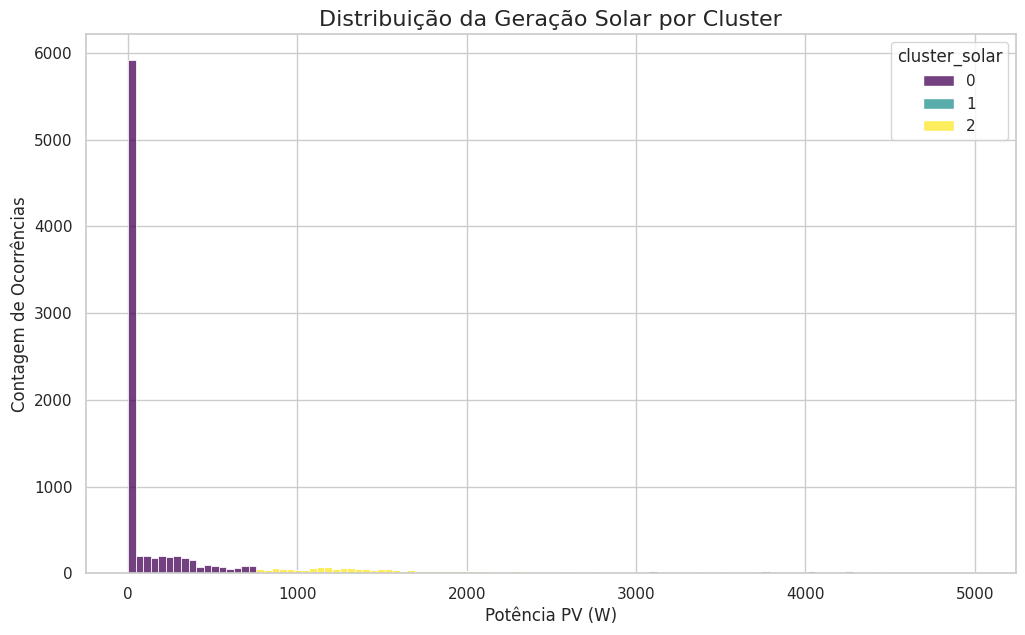

In [ ]:
features_solar = ['pv1Power']

#Criação de um novo df apenas com as colunas de features
df_cluster_solar = df_maio[features_solar].dropna()

#2. Escalonamento
scaler = StandardScaler()
df_solar_scaled = scaler.fit_transform(df_cluster_solar)

# 3. Treinar o modelo K-Means
kmeans_solar = KMeans(n_clusters=3, random_state=42, n_init='auto')
kmeans_solar.fit(df_solar_scaled)

# 4. Adicionar os resultados (os clusters) de volta ao DataFrame
df_cluster_solar['cluster_solar'] = kmeans_solar.labels_

# 5. Analisar os clusters para entender o que cada um representa
cluster_analysis_solar = df_cluster_solar.groupby('cluster_solar')[features_solar].mean()

print("Análise dos Clusters para produção solar (valores médios por cluster):")
display(cluster_analysis_solar)
# Supondo que 'df_maio' é o seu DataFrame e já tem a coluna 'estado_solar_cluster'

plt.figure(figsize=(12, 7))

# Usamos o Seaborn para criar um histograma onde a cor (hue) é baseada no cluster
sns.histplot(data=df_cluster_solar, x='pv1Power', hue='cluster_solar', palette='viridis', multiple='stack')

plt.title('Distribuição da Geração Solar por Cluster', fontsize=16)
plt.xlabel('Potência PV (W)', fontsize=12)
plt.ylabel('Contagem de Ocorrências', fontsize=12)
plt.show()

## Outliers

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Supondo que 'df_maio' é o seu DataFrame já limpo e com o índice de tempo.

# --- PASSO 1: Definir o estado "Sem Geração" com uma regra manual ---

# Define um limiar de potência baixo (em Watts) para considerar "Sem Geração".
# Isso é útil para ignorar pequenos ruídos do sensor.
limiar_geracao_zero = 10.0

# Cria a coluna final que armazenará os rótulos dos nossos estados.
# Inicializamos com um valor que indica "não classificado".
df_maio['estado_solar_hibrido'] = -1

# Aplica a regra: tudo abaixo do limiar é o estado 0.
df_maio.loc[df_maio['pv1Power'] < limiar_geracao_zero, 'estado_solar_hibrido'] = 0

print(f"--- Passo 1 Concluído ---")
print(f"{len(df_maio[df_maio['estado_solar_hibrido'] == 0])} pontos classificados como 'Sem Geração'.")


# --- PASSO 2: Clusterizar APENAS os dados restantes (com geração) ---

# Filtra o DataFrame para pegar apenas os dados onde há geração real.
# É importante usar .copy() para evitar avisos do pandas.
df_com_geracao = df_maio[df_maio['estado_solar_hibrido'] == -1].copy()

# Verificamos se há dados para clusterizar
if not df_com_geracao.empty:
    print("\n--- Passo 2 Iniciado: Clusterizando dados com geração ativa ---")

    # Prepara os dados para o K-Means (escalonamento)
    features_solar = ['pv1Power']
    scaler = StandardScaler()
    df_solar_scaled = scaler.fit_transform(df_com_geracao[features_solar])

    # Treina o K-Means para encontrar 2 clusters (Médio e Alto) nos dados restantes.
    kmeans_solar = KMeans(n_clusters=2, random_state=42, n_init='auto')

    # O K-Means irá gerar rótulos 0 e 1.
    labels_kmeans = kmeans_solar.fit_predict(df_solar_scaled)

    # Para evitar conflito com o estado 0 que já criamos, somamos 1 aos novos clusters.
    # Agora teremos os clusters 1 (Geração Média) e 2 (Geração Alta).
    df_com_geracao['cluster_temp'] = labels_kmeans + 1

    # Atualiza a coluna final no DataFrame principal com os novos clusters encontrados.
    df_maio['estado_solar_hibrido'].update(df_com_geracao['cluster_temp'])
    print("Clusterização dos dados restantes concluída.")
else:
    print("\nAVISO: Não foram encontrados dados com geração ativa para clusterizar.")

# --- PASSO 3: Juntar e Analisar os Resultados Finais ---

# Cria um mapa para nomear os clusters de forma legível
# (Os nomes exatos podem ser ajustados após ver as médias)
mapa_solar_hibrido = {
    0: 'Sem Geração',
    1: 'Geração Média',
    2: 'Geração Alta'
}

# Aplica o mapa para criar uma coluna com os nomes
df_maio['estado_solar_nome'] = df_maio['estado_solar_hibrido'].map(mapa_solar_hibrido)

print("\n--- Passo 3 Concluído: Análise Final ---")
print("Análise dos 3 estados solares encontrados (Abordagem Híbrida):")

# Agrupa pelos nomes dos estados e mostra as estatísticas de cada um
analise_final = df_maio.groupby('estado_solar_nome')['pv1Power'].agg(['mean', 'min', 'max', 'count'])
display(analise_final)

--- Passo 1 Concluído ---
5677 pontos classificados como 'Sem Geração'.

--- Passo 2 Iniciado: Clusterizando dados com geração ativa ---
Clusterização dos dados restantes concluída.

--- Passo 3 Concluído: Análise Final ---
Análise dos 3 estados solares encontrados (Abordagem Híbrida):


/tmp/ipython-input-1948473011.py:50: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_maio['estado_solar_hibrido'].update(df_com_geracao['cluster_temp'])


,mean,min,max,count
estado_solar_nome,,,,
Geração Alta,3107.522241,1862.4,4992.833333,926
Geração Média,606.916581,10.5,1859.800000,3477
Sem Geração,0.128859,0.0,9.666667,5677


## Manual + K-Means

In [ ]:
import pandas as pd

# Supondo que 'df_maio' é o seu DataFrame já limpo e com o índice de tempo.

# --- 1. Selecione a coluna para análise ---
coluna_solar = 'pv1Power'
dados_solares = df_maio[coluna_solar].dropna()

print(f"--- Análise de Outliers (IQR) para a coluna: '{coluna_solar}' ---")

# --- 2. Calcule Q1, Q3 e IQR ---
Q1 = dados_solares.quantile(0.25)
Q3 = dados_solares.quantile(0.75)
IQR = Q3 - Q1

# --- 3. Calcule os Limites de Normalidade ---
# A fórmula padrão para identificar outliers
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"  Quartil 1 (Q1): {Q1:.2f} W")
print(f"  Quartil 3 (Q3): {Q3:.2f} W")
print(f"  Amplitude Interquartil (IQR): {IQR:.2f} W")
print(f"  --------------------------------------------------")
print(f"  Limite Inferior (estatístico): {limite_inferior:.2f} W")
print(f"  Limite Superior (estatístico): {limite_superior:.2f} W")
print(f"  --------------------------------------------------")


# --- 4. Identifique os Outliers ---
# Filtra o DataFrame para encontrar os pontos fora dos limites
outliers_solares = df_maio[
    (df_maio[coluna_solar] < limite_inferior) |
    (df_maio[coluna_solar] > limite_superior)
]

# --- 5. Apresente os Resultados ---
print(f"\nResultado da Análise:")
if not outliers_solares.empty:
    print(f"  -> Foram encontrados {len(outliers_solares)} outliers de produção solar.")
    print("  Estes são pontos onde a geração foi anormalmente alta.")
    print("\n  Exemplos de outliers encontrados (valores mais altos):")
    # Mostra os 5 maiores outliers
    display(outliers_solares.sort_values(by=coluna_solar, ascending=False).head())
else:
    print("  -> Nenhum outlier de produção solar foi encontrado.")

In [ ]:
# Cria um novo DataFrame contendo apenas os dados 'normais'
df_solar_normal = df_maio[df_maio[coluna_solar] <= limite_superior]

print(f"\nTamanho do DataFrame original: {len(df_maio)}")
print(f"Tamanho do DataFrame após remover outliers solares: {len(df_solar_normal)}")

## DBScan

In [ ]:
import pandas as pd
import numpy as np
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Supondo que 'df_maio' é o seu DataFrame
features_solar = ['pv1Power']
df_cluster_solar = df_maio[features_solar].dropna().copy()

# O escalonamento é fundamental
scaler = StandardScaler()
df_solar_scaled = scaler.fit_transform(df_cluster_solar)

# --- PASSO 1: Encontrar o `eps` ideal ---

# Escolha um valor para 'k' (min_samples). Um bom ponto de partida
# é um valor que você considera o tamanho mínimo de um cluster real. Vamos usar 100.
k = 100

# Calcula a distância de cada ponto para seus k vizinhos
neighbors = NearestNeighbors(n_neighbors=k)
neighbors_fit = neighbors.fit(df_solar_scaled)
distances, indices = neighbors_fit.kneighbors(df_solar_scaled)

# Pega a distância para o k-ésimo vizinho (a última coluna) e ordena
k_distances = np.sort(distances[:, -1])

# Plota o gráfico
plt.figure(figsize=(12, 7))
plt.plot(k_distances)
plt.xlabel("Pontos de Dados (ordenados por distância)")
plt.ylabel(f"Distância para o {k}º Vizinho Mais Próximo")
plt.title("Gráfico de Distância k-NN para Escolha do `eps` do DBSCAN")
plt.grid(True)
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt

# Supondo que 'df_maio' é o seu DataFrame
features_solar = ['pv1Power']
df_cluster_solar = df_maio[features_solar].dropna().copy()

# O escalonamento é crucial para o DBSCAN, pois ele é baseado em distância
scaler = StandardScaler()
df_solar_scaled = scaler.fit_transform(df_cluster_solar)

# --- Implementação do DBSCAN ---
# Estes parâmetros 'eps' e 'min_samples' são um ponto de partida.
# Você pode precisar ajustá-los para os seus dados.
# Um 'eps' menor encontrará clusters mais densos.
dbscan = DBSCAN(eps=0.08, min_samples=100) # Exemplo de valores
clusters_dbscan = dbscan.fit_predict(df_solar_scaled)

# Adiciona os resultados ao DataFrame
df_maio['cluster_dbscan'] = clusters_dbscan

# O DBSCAN rotula o ruído/outliers como -1. Vamos ver o que ele encontrou.
print("--- Resultados do DBSCAN ---")
print("Contagem de pontos por cluster (cluster -1 é ruído):")
print(pd.Series(clusters_dbscan).value_counts())


# --- Análise e Visualização ---
# Para a análise, vamos ignorar o ruído por enquanto
df_analise_dbscan = df_maio[df_maio['cluster_dbscan'] != -1]

# Analisar os clusters encontrados
cluster_analysis_dbscan = df_analise_dbscan.groupby('cluster_dbscan')[features_solar].mean()
print("\nAnálise dos Clusters encontrados pelo DBSCAN (valores médios):")
display(cluster_analysis_dbscan)

# Visualizar o resultado
plt.figure(figsize=(12, 7))
sns.histplot(data=df_maio, x='pv1Power', hue='cluster_dbscan', palette='viridis', multiple='stack')
plt.title('Distribuição da Geração Solar por Cluster (DBSCAN)', fontsize=16)
plt.xlabel('Potência PV (W)', fontsize=12)
plt.ylabel('Contagem de Ocorrências', fontsize=12)
plt.show()

NameError: name 'df_maio' is not defined

# Passo a passo

graph TD  A[Dados em Tempo Real] --> L1{Anomalia de Valor? (IQR)};

    L1 -- Sim --> Z[ALARME: Valor Inválido!];

    L1 -- Não --> L2{Determinar Cluster e Distância};

    L2 --> L2a{Distância ao Centroide > Limiar?};

    L2a -- Sim --> Z2[ALARME: Estado Desconhecido!];

    L2a -- Não --> L3{Transição Válida no EBAM?};

    L3 -- Não --> Z3[ALARME: Sequência Inválida!];

    L3 -- Sim --> L4{Duração no Estado > Limiar?};

    L4 -- Sim --> Z4[ALARME: Duração Anômala!];

    L4 -- Não --> F[Comportamento Normal -> Atualizar Estado];
    
    F --> A;